## Lasso and Ridge Regularization Techniques

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
dataset = pd.read_csv('kc_house_data_NaN.csv')
dataset.head(3)

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062


In [3]:
dataset.columns

Index(['Unnamed: 0', 'id', 'date', 'price', 'bedrooms', 'bathrooms',
       'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition',
       'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated',
       'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')

In [4]:
df = dataset[['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'price']]

In [5]:
df.head(3)

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price
0,3.0,1.00,1180,5650,1.0,0,0,3,1180,0,1955,0,221900.0
1,3.0,2.25,2570,7242,2.0,0,0,3,2170,400,1951,1991,538000.0
2,2.0,1.00,770,10000,1.0,0,0,3,770,0,1933,0,180000.0


In [6]:
df.shape

(21613, 13)

In [7]:
# check the missing/null values
df.isnull().sum()

bedrooms         13
bathrooms        10
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
price             0
dtype: int64

In [8]:
# for now drop null values
df.dropna(inplace=True)

C:\Users\riazu\AppData\Local\Temp\ipykernel_5856\3181870889.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [9]:
df.shape

(21597, 13)

In [10]:
# Again, check the missing/null values
df.isnull().sum()

bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
price            0
dtype: int64

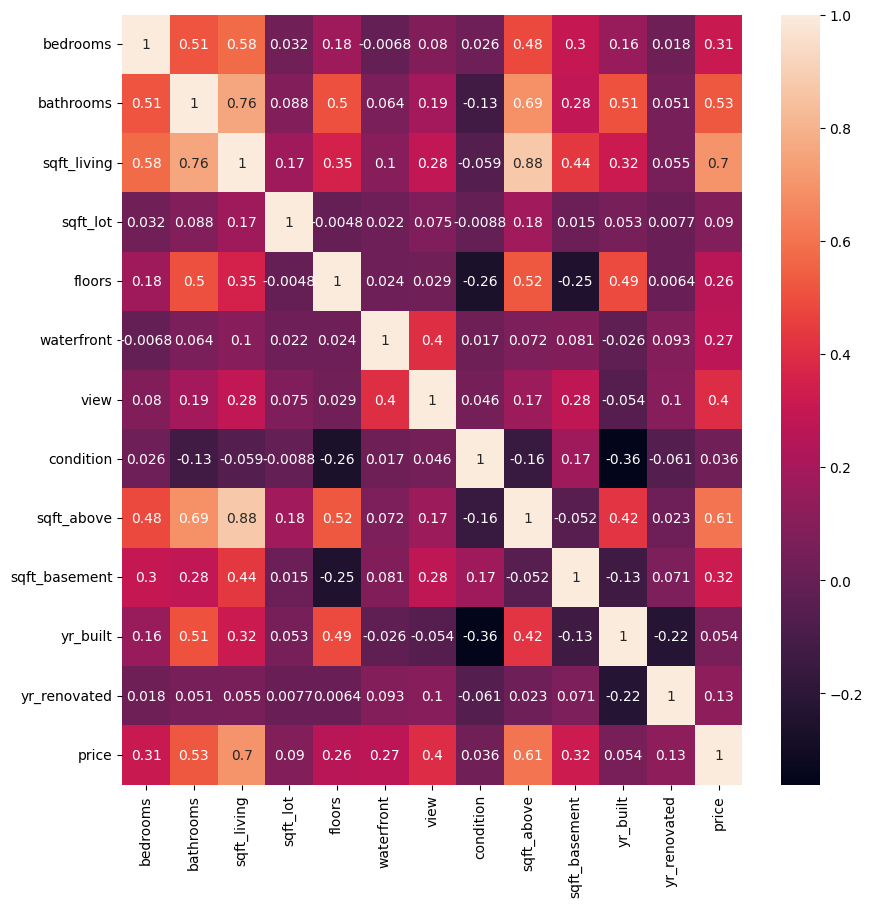

In [11]:
# Plot heatmap to check the correlation/relationship between features
plt.figure(figsize=(10, 10))
sns.heatmap(data=df.corr(), annot=True)
plt.show()

In [12]:
# Create Input and Output variables
x = df.iloc[:, :-1]
y = df['price']

In [13]:
# Perform Scaling on input data to balance it
sc = StandardScaler()
sc.fit(x)
x = pd.DataFrame(sc.transform(x), columns=x.columns)
x

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
0,-0.402903,-1.451073,-0.980652,-0.228182,-0.915552,-0.087205,-0.305715,-0.629986,-0.735251,-0.659031,-0.544678,-0.210210
1,-0.402903,0.174486,0.533369,-0.189739,0.937431,-0.087205,-0.305715,-0.629986,0.460776,0.244602,-0.680850,4.744842
2,-1.482493,-1.451073,-1.427234,-0.123139,-0.915552,-0.087205,-0.305715,-0.629986,-1.230575,-0.659031,-1.293626,-0.210210
3,0.676687,1.149821,-0.131057,-0.243878,-0.915552,-0.087205,-0.305715,2.444427,-0.892305,1.396734,-0.204247,-0.210210
4,-0.402903,-0.150626,-0.436040,-0.169503,-0.915552,-0.087205,-0.305715,-0.629986,-0.131197,-0.659031,0.544700,-0.210210
...,...,...,...,...,...,...,...,...,...,...,...,...
21592,-0.402903,0.499597,-0.599424,-0.337306,2.790414,-0.087205,-0.305715,-0.629986,-0.312413,-0.659031,1.293648,-0.210210
21593,0.676687,0.499597,0.250171,-0.224246,0.937431,-0.087205,-0.305715,-0.629986,0.629911,-0.659031,1.463863,-0.210210
21594,-1.482493,-1.776184,-1.154928,-0.332018,0.937431,-0.087205,-0.305715,-0.629986,-0.928548,-0.659031,1.293648,-0.210210
21595,-0.402903,0.499597,-0.523178,-0.306952,0.937431,-0.087205,-0.305715,-0.629986,-0.227845,-0.659031,1.123432,-0.210210


In [14]:
# Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [15]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

### Linear Regression

In [17]:
# Initialize and train linear regression
lr = LinearRegression()
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[-57891.79, 49792.71,131331.35,..., 48276.75,-85742.53, 4264.13]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['bedrooms','bathrooms','sqft_living',...,'sqft_basement','yr_built', 'yr_renovated']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.406e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [18]:
lr.score(x_test, y_test)

0.5830619270504811

In [19]:
print('MSE: ', mean_squared_error(y_test, lr.predict(x_test)))
print('MAE: ', mean_absolute_error(y_test, lr.predict(x_test)))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, lr.predict(x_test))))

MSE:  54241227208.47646
MAE:  154798.6508825103
RMSE:  232897.46071710714


In [20]:
lr.coef_

array([-57891.78833405,  49792.7115278 , 131331.34848585, -16856.40067386,
        25748.80840822,  45894.39700186,  47448.63091684,  13207.19727911,
       119848.24377184,  48276.74793424, -85742.5251365 ,   4264.13404179])

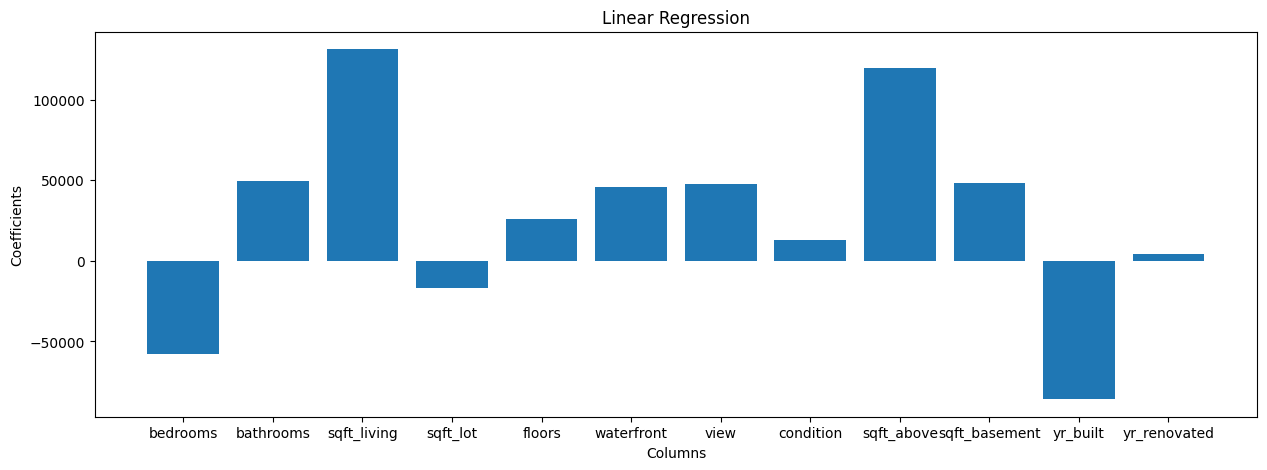

In [21]:
# Plot/display the coefficients
plt.figure(figsize=(15,5))
plt.bar(x.columns, lr.coef_)
plt.title('Linear Regression')
plt.xlabel('Columns')
plt.ylabel('Coefficients')
plt.show()

### Lasso Regression - L1 Regularization Technique

- used for feature selection

In [22]:
la = Lasso(alpha=5) # alpha is the penalty/lambda
la.fit(x_train, y_train)

C:\Users\riazu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.983455e+13, tolerance: 2.349e+11
  model = cd_fast.enet_coordinate_descent(


,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",5
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [23]:
la.score(x_test, y_test)

0.5830653384945517

In [24]:
print('MSE: ', mean_squared_error(y_test, la.predict(x_test)))
print('MAE: ', mean_absolute_error(y_test, la.predict(x_test)))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, la.predict(x_test))))

MSE:  54240783399.37159
MAE:  154798.47497563512
RMSE:  232896.5079157942


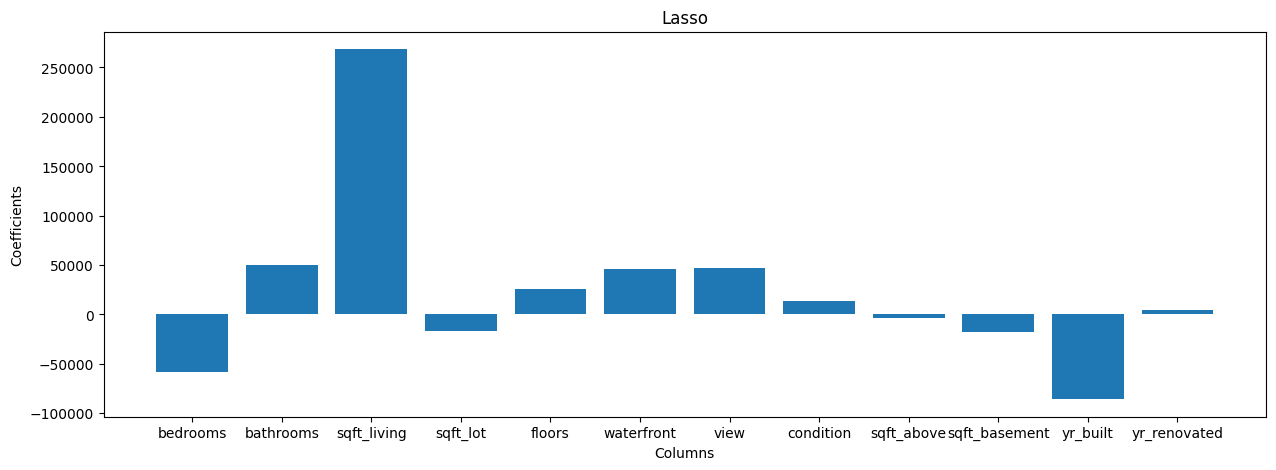

In [25]:
# Plot/display the coefficients
plt.figure(figsize=(15,5))
plt.bar(x.columns, la.coef_)
plt.title('Lasso')
plt.xlabel('Columns')
plt.ylabel('Coefficients')
plt.show()

### Ridge Regression - L2 Regularization Technique

- Reduces Overfitting

In [26]:
ri = Ridge(alpha=10)
ri.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' t

In [27]:
ri.score(x_test, y_test)

0.5831091064597262

In [28]:
print('MSE: ', mean_squared_error(y_test, ri.predict(x_test)))
print('MAE: ', mean_absolute_error(y_test, ri.predict(x_test)))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, ri.predict(x_test))))

MSE:  54235089440.72998
MAE:  154781.2234454839
RMSE:  232884.28336993887


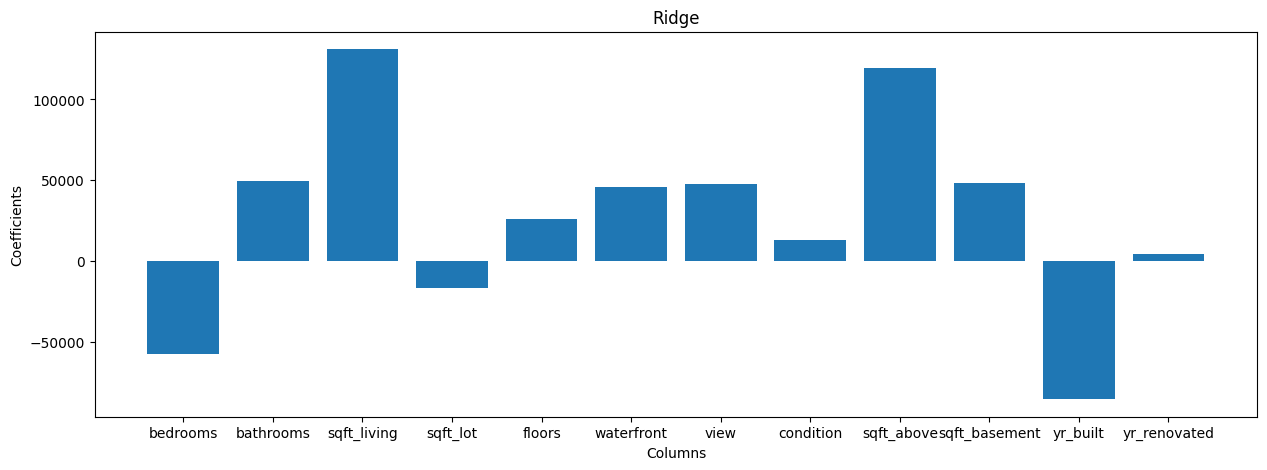

In [29]:
# Plot/display the coefficients
plt.figure(figsize=(15,5))
plt.bar(x.columns, ri.coef_)
plt.title('Ridge')
plt.xlabel('Columns')
plt.ylabel('Coefficients')
plt.show()

In [30]:
# compare the  coefficients of three models
df = pd.DataFrame({'col_name':x.columns, 'LinearRegression':lr.coef_, 'Lasso':la.coef_, 'Ridge':ri.coef_})
df

,col_name,LinearRegression,Lasso,Ridge
0,bedrooms,-57891.788334,-57885.488594,-57758.030030
1,bathrooms,49792.711528,49759.732920,49777.365449
2,sqft_living,131331.348486,268633.549765,131235.918777
3,sqft_lot,-16856.400674,-16850.407668,-16821.849012
4,floors,25748.808408,25751.769924,25741.442130
5,waterfront,45894.397002,45891.401664,45879.564217
6,view,47448.630917,47446.669831,47468.418993
7,condition,13207.197279,13201.842419,13221.701829
8,sqft_above,119848.243772,-3924.966838,119754.248071
9,sqft_basement,48276.747934,-17906.511096,48254.589689
